<a href="https://colab.research.google.com/github/mukilarasiu2025cse/FUNDAMENTAL-OF-DATA-SCIENCE-CS23334/blob/main/Reg_No_250701457_Name_Mukil_Arasi_U_Exp_No_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

         Date              Product  Sales  Quantity           Region
0  01-01-2023  Product A (Updated)  220.0       4.4  North (Updated)
1  02-01-2023  Product B (Updated)  165.0       3.3  South (Updated)
2  03-01-2023  Product A (Updated)  242.0       5.5  North (Updated)
3  04-01-2023  Product C (Updated)  330.0       6.6   East (Updated)
4  05-01-2023  Product B (Updated)  198.0       4.4   West (Updated)
Date        0
Product     0
Sales       0
Quantity    0
Region      0
dtype: int64
            Sales   Quantity
count   16.000000  16.000000
mean   261.250000   5.912500
std     70.434367   1.921067
min    165.000000   3.300000
25%    206.250000   4.400000
50%    247.500000   6.050000
75%    332.750000   7.700000
max    374.000000   8.800000
               Product   Sales  Quantity
0  Product A (Updated)  1485.0      36.3
1  Product B (Updated)   935.0      18.7
2  Product C (Updated)  1760.0      39.6


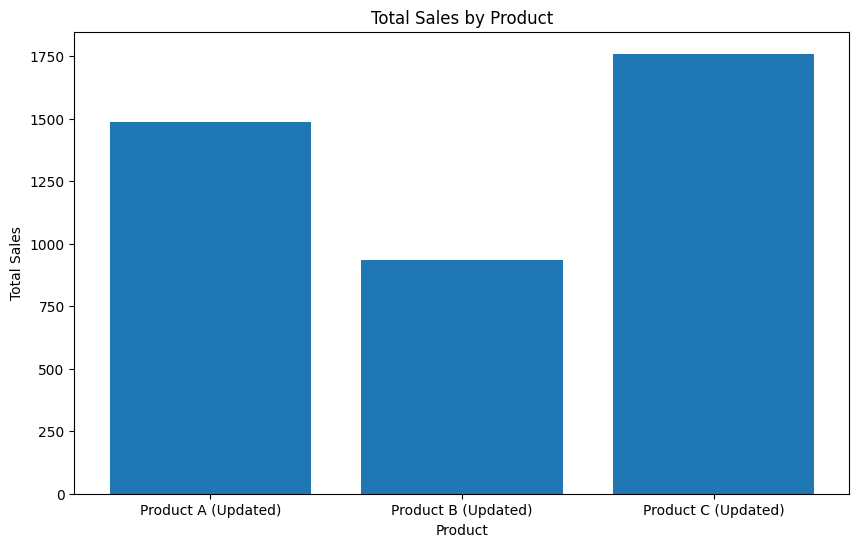

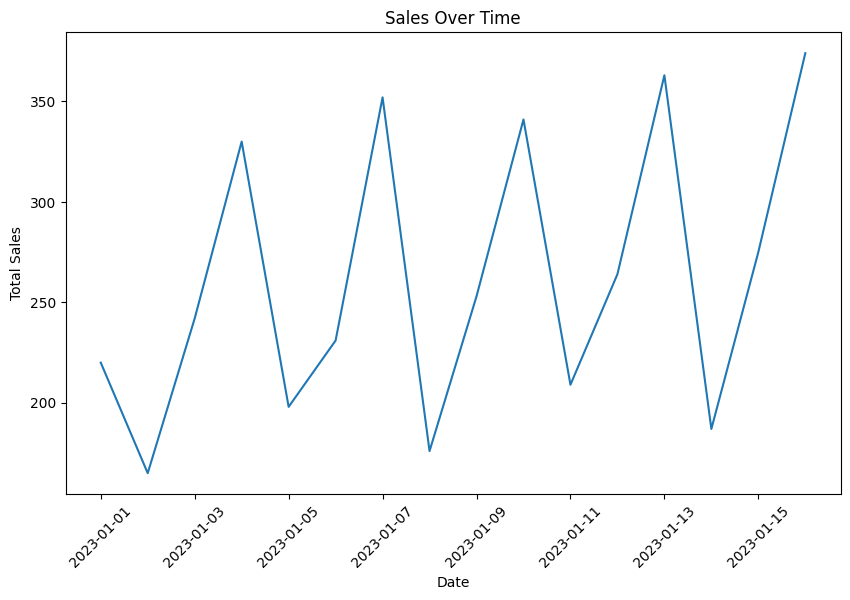

Product          Product A (Updated)  Product B (Updated)  Product C (Updated)
Region                                                                        
East (Updated)                   0.0                  0.0               1760.0
North (Updated)               1485.0                  0.0                  0.0
South (Updated)                  0.0                528.0                  0.0
West (Updated)                   0.0                407.0                  0.0
             Sales  Quantity
Sales     1.000000  0.944922
Quantity  0.944922  1.000000


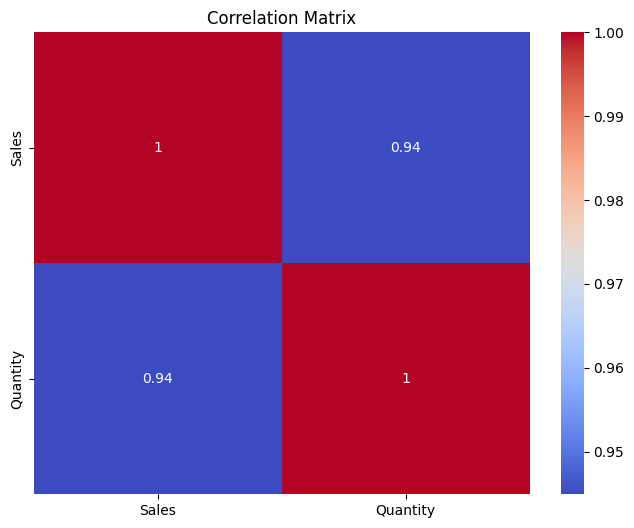

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
file_path = 'sales-data-new.csv'
df = pd.read_csv(file_path)

# Display first five rows
print(df.head())

# Check for missing values
print(df.isnull().sum())

# Fill missing Sales values with mean
df['Sales'] = df['Sales'].fillna(df['Sales'].mean())

# Drop rows with missing important values
df.dropna(subset=['Product', 'Quantity', 'Region'], inplace=True)

# Summary statistics
print(df.describe())

# Group by Product and calculate total Sales and Quantity
product_summary = df.groupby('Product').agg({
    'Sales': 'sum',
    'Quantity': 'sum'
}).reset_index()

print(product_summary)

# Bar plot of total sales by product
plt.figure(figsize=(10, 6))
plt.bar(product_summary['Product'], product_summary['Sales'])
plt.xlabel('Product')
plt.ylabel('Total Sales')
plt.title('Total Sales by Product')
plt.show()

# Convert Date into datetime format
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)

# Line plot of sales over time
sales_over_time = df.groupby('Date').agg({
    'Sales': 'sum'
}).reset_index()

plt.figure(figsize=(10, 6))
plt.plot(sales_over_time['Date'], sales_over_time['Sales'])
plt.xlabel('Date')
plt.ylabel('Total Sales')
plt.title('Sales Over Time')
plt.xticks(rotation=45)
plt.show()

# Pivot table to analyze sales by Region and Product
pivot_table = df.pivot_table(
    values='Sales',
    index='Region',
    columns='Product',
    aggfunc='sum',
    fill_value=0
)

print(pivot_table)

# Correlation matrix
correlation_matrix = df[['Sales', 'Quantity']].corr()

print(correlation_matrix)

# Heatmap of correlation matrix
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()